# 02 – Phân tích dữ liệu tiểu hành tinh

**Câu hỏi Q1 · Chủ nhiệm: Nghiêm**

Dữ liệu: `data/raw/dataset.csv`. Chọn **Restart Kernel → Run All**. Đặt `FETCH_JPL = False` nếu chỉ chạy phần dữ liệu Kaggle.

## Q1 – Nhóm tiểu hành tinh nào có dữ liệu đầy đủ hơn và độ bất định ước lượng của bán trục lớn thấp hơn?

Trong các nhóm quỹ đạo của tiểu hành tinh (`class`), nhóm nào có tỷ lệ bản ghi đầy đủ thông tin vật lý (có đồng thời đường kính `diameter` và độ phản xạ `albedo`) cao hơn, đồng thời có độ bất định quỹ đạo thấp hơn? Sự khác biệt giữa các nhóm có còn tồn tại khi so sánh các tiểu hành tinh ở cùng mức độ sáng tuyệt đối (`H`) hay không? Trên mẫu bổ sung, lịch sử quan sát của các nhóm khác nhau như thế nào?

**Ý nghĩa đối với nhà nghiên cứu:** Xác định nhóm có dữ liệu phù hợp để nghiên cứu đặc điểm vật lý và quỹ đạo; nhận diện những nhóm còn thiếu thông tin.

- Phân nhóm chính theo `class`.
- Phân nhóm theo 5 phân vị độ sáng tuyệt đối `H_bin` (Q1–Q5).
- Phân tích chính chỉ giữ các nhóm quỹ đạo có ít nhất 1.000 bản ghi.
- Khi chuẩn hóa theo độ sáng, mỗi nhóm `class × H_bin` cần có ít nhất 30 quan sát hợp lệ cho chỉ số tương ứng.

In [1]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

from pathlib import Path
import time
import json
import hashlib
import platform
from datetime import datetime, timezone
from IPython.display import display, Markdown

FETCH_JPL = True
N_BOOT = 500
RANDOM_SEED = 42
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 150)


# ============================================================
# 2. LOAD DATASET
# ============================================================

DATA_PATH = Path("data/raw/dataset.csv")
if not DATA_PATH.exists() and (Path.cwd().parent / DATA_PATH).exists():
    DATA_PATH = Path.cwd().parent / DATA_PATH
PROJECT_ROOT = DATA_PATH.resolve().parents[2]
RESULT_DIR = PROJECT_ROOT / "data/processed/q1_results"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Không tìm thấy dataset tại: {DATA_PATH.resolve()}"
    )

df_raw = pd.read_csv(DATA_PATH, low_memory=False)
df_raw.columns = df_raw.columns.astype(str).str.strip()

print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)
print("Dataset path:", DATA_PATH.resolve())
print("Number of rows:", f"{len(df_raw):,}")
print("Number of columns:", df_raw.shape[1])

display(df_raw.head())


# ============================================================
# 3. CHECK REQUIRED COLUMNS AND IDENTIFIER
# ============================================================

required_cols = [
    "class", "H", "diameter", "albedo",
    "a", "sigma_a", "rms"
]

missing_required = [
    col for col in required_cols
    if col not in df_raw.columns
]

if missing_required:
    raise KeyError(
        f"Dataset đang thiếu các cột bắt buộc: {missing_required}"
    )

id_candidates = ["spkid", "pdes"]
id_col = next(
    (col for col in id_candidates if col in df_raw.columns),
    None
)

print("Required columns:", required_cols)
print("Identifier column:", id_col)

if id_col is None:
    print(
        "CẢNH BÁO: Không tìm thấy spkid hoặc pdes. "
        "Phần bổ sung dữ liệu NASA/JPL sẽ được bỏ qua."
    )


# ============================================================
# 4. CHECK MISSING VALUES IN RAW DATA
# ============================================================

check_cols = required_cols.copy()

if id_col is not None:
    check_cols.append(id_col)

missing_summary = pd.DataFrame({
    "Missing count": df_raw[check_cols].isna().sum(),
    "Missing percentage (%)": (
        df_raw[check_cols].isna().mean() * 100
    ).round(2),
    "Available count": df_raw[check_cols].notna().sum()
})

display(missing_summary)

DATASET INFORMATION
Dataset path: /home/hohuunghiem/LTKHDL/P4DS/data/raw/dataset.csv
Number of rows: 958,524
Number of columns: 45


,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,albedo,diameter_sigma,orbit_id,epoch,epoch_mjd,epoch_cal,equinox,e,a,q,i,om,w,ma,ad,n,tp,tp_cal,per,per_y,moid,moid_ld,sigma_e,sigma_a,sigma_q,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,class,rms
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40,939.400,0.0900,0.200,JPL 47,2458600.5,58600,20190427.0,J2000,0.076009,2.769165,2.558684,10.594067,80.305531,73.597695,77.372098,2.979647,0.213885,2.458239e+06,2.018043e+07,1683.145703,4.608202,1.59478,620.640533,4.819000e-12,1.032800e-11,1.956900e-11,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,MBA,0.43301
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20,545.000,0.1010,18.000,JPL 37,2459000.5,59000,20200531.0,J2000,0.229972,2.773841,2.135935,34.832932,173.024741,310.202392,144.975675,3.411748,0.213345,2.458321e+06,2.018072e+07,1687.410992,4.619880,1.23429,480.348639,3.193400e-08,4.033700e-09,8.832200e-08,3.469400e-06,6.272400e-06,9.128200e-06,8.859100e-06,4.961300e-09,4.653600e-10,4.078700e-05,3.680700e-06,MBA,0.35936
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33,246.596,0.2140,10.594,JPL 112,2459000.5,59000,20200531.0,J2000,0.256936,2.668285,1.982706,12.991043,169.851482,248.066193,125.435355,3.353865,0.226129,2.458446e+06,2.018112e+07,1592.013769,4.358696,1.03429,402.514639,3.052000e-08,3.471800e-09,8.139200e-08,3.223100e-06,1.664600e-05,1.772100e-05,8.110400e-06,4.363900e-09,4.413400e-10,3.528800e-05,3.107200e-06,MBA,0.33848
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00,525.400,0.4228,0.200,JPL 35,2458600.5,58600,20190427.0,J2000,0.088721,2.361418,2.151909,7.141771,103.810804,150.728541,95.861938,2.570926,0.271609,2.458248e+06,2.018051e+07,1325.432763,3.628837,1.13948,443.451432,2.332100e-10,1.514300e-09,1.928600e-09,2.170600e-07,3.880800e-07,1.789300e-07,1.206800e-06,1.648600e-09,2.612500e-10,4.103700e-06,1.274900e-06,MBA,0.39980
4,a0000005,2000005,5 Astraea,5,Astraea,NaN,N,N,6.90,106.699,0.2740,3.140,JPL 114,2459000.5,59000,20200531.0,J2000,0.190913,2.574037,2.082619,5.367427,141.571026,358.648418,17.846343,3.065455,0.238661,2.458926e+06,2.020032e+07,1508.414421,4.129814,1.09575,426.433027,2.373700e-08,3.970900e-09,6.092400e-08,2.740800e-06,2.894900e-05,2.984200e-05,8.303800e-06,4.729000e-09,5.522700e-10,3.474300e-05,3.490500e-06,MBA,0.52191


Required columns: ['class', 'H', 'diameter', 'albedo', 'a', 'sigma_a', 'rms']
Identifier column: spkid


,Missing count,Missing percentage (%),Available count
class,0,0.00,958524
H,6263,0.65,952261
diameter,822315,85.79,136209
albedo,823421,85.91,135103
a,0,0.00,958524
sigma_a,19922,2.08,938602
rms,2,0.00,958522
spkid,0,0.00,958524


## Tiền xử lý

Ở bước này, dữ liệu được chuẩn bị để bảo đảm các phép tính và so sánh giữa các nhóm được thực hiện trên những giá trị hợp lệ.

Các công việc chính:

1. Tạo bản sao dữ liệu gốc để không làm thay đổi `df_raw`.
2. Chuyển các biến vật lý và quỹ đạo về kiểu số.
3. Kiểm tra và loại bỏ các bản ghi trùng lặp hoàn toàn.
4. Chuyển các giá trị không hợp lệ thành missing values.
5. Tạo biến thể hiện mức độ đầy đủ thông tin vật lý và độ bất định tương đối của quỹ đạo.
6. Chia độ sáng tuyệt đối thành 5 nhóm phân vị để phục vụ so sánh.

**Lưu ý:** Không loại bỏ bản ghi chỉ vì thiếu `diameter` hoặc `albedo`. Mức độ thiếu hụt của hai biến này chính là một nội dung cần phân tích. Các bản ghi thiếu `class` hoặc `H` vẫn được giữ trong bản dữ liệu đã làm sạch, nhưng không thể tham gia phân tích phân nhóm tương ứng.

In [2]:
# ============================================================
# 1. CREATE WORKING COPY
# ============================================================

df = df_raw.copy()
print("Rows in original dataset:", f"{len(df):,}")


# ============================================================
# 2. CONVERT DATA TYPES
# ============================================================

numeric_cols = [
    "H", "diameter", "albedo",
    "a", "sigma_a", "rms"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df[numeric_cols] = df[numeric_cols].replace(
    [np.inf, -np.inf], np.nan
)

df["class"] = (
    df["class"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

print("Numeric columns converted.")


# ============================================================
# 3. REMOVE EXACT DUPLICATE RECORDS
# ============================================================

rows_before = len(df)
duplicate_count = int(df.duplicated().sum())

df = df.drop_duplicates().copy()

if id_col is not None:
    keys = df[id_col].astype("string").str.strip().str.replace(r"\.0$", "", regex=True)
    repeated = keys.notna() & keys.duplicated(keep=False)
    if repeated.any():
        display(df.loc[repeated, [id_col, "class"]].head(20))
        raise ValueError("Có mã tiểu hành tinh lặp sau khi bỏ dòng trùng hoàn toàn. Cần xác định bản ghi/epoch cần giữ trước khi phân tích; không tự chọn tùy ý.")

print("Exact duplicate records:", f"{duplicate_count:,}")
print("Rows before duplicate removal:", f"{rows_before:,}")
print("Rows after duplicate removal:", f"{len(df):,}")


# ============================================================
# 4. HANDLE INVALID VALUES
# ============================================================

invalid_rules = {
    "diameter": df["diameter"] <= 0,
    "albedo": df["albedo"] <= 0,
    "a": df["a"] <= 0,
    "sigma_a": df["sigma_a"] < 0,
    "rms": df["rms"] < 0
}

invalid_summary = {}

for col, condition in invalid_rules.items():
    invalid_count = int(condition.sum())
    df.loc[condition, col] = np.nan
    invalid_summary[col] = invalid_count

print("Invalid values converted to missing values:")
display(pd.Series(invalid_summary, name="Invalid count").to_frame())


# ============================================================
# 5. CREATE DERIVED VARIABLES
# ============================================================

df["physical_complete"] = (
    df["diameter"].notna() &
    df["albedo"].notna()
).astype(int)

df["relative_sigma_a_pct"] = np.nan

valid_orbit = (
    df["a"].notna() &
    df["sigma_a"].notna() &
    (df["a"] > 0) &
    (df["sigma_a"] >= 0)
)

df.loc[valid_orbit, "relative_sigma_a_pct"] = (
    100 * df.loc[valid_orbit, "sigma_a"]
    / df.loc[valid_orbit, "a"]
)


# ============================================================
# 6. DIVIDE ABSOLUTE MAGNITUDE INTO FIVE QUANTILE GROUPS
# ============================================================

df["H_bin"] = pd.Series(
    pd.NA, index=df.index, dtype="string"
)

valid_H = df["H"].notna()

if df.loc[valid_H, "H"].nunique() < 2:
    raise ValueError(
        "Không đủ giá trị H khác nhau để chia nhóm phân vị."
    )

h_codes = pd.qcut(
    df.loc[valid_H, "H"],
    q=5,
    labels=False,
    duplicates="drop"
)

df.loc[valid_H, "H_bin"] = h_codes.map(
    lambda x: f"Q{int(x) + 1}"
).astype("string")

H_ORDER = sorted(
    df["H_bin"].dropna().unique(),
    key=lambda x: int(x.replace("Q", ""))
)

print("Absolute magnitude groups:", H_ORDER)


# ============================================================
# 7. PREPROCESSING SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("PREPROCESSING SUMMARY")
print("=" * 60)

print("Rows after preprocessing:", f"{len(df):,}")
print("Columns after preprocessing:", df.shape[1])
print(
    "Physical completeness rate:",
    f"{df['physical_complete'].mean() * 100:.2f}%"
)

print("\nOrbital class distribution:")
display(df["class"].value_counts(dropna=False).head(15))

print("\nAbsolute magnitude distribution:")
display(df["H_bin"].value_counts().sort_index())

print("\nMissing values after preprocessing:")
display(
    df[required_cols].isna().sum().to_frame("Missing count")
)

display(df.head())

Rows in original dataset: 958,524
Numeric columns converted.
Exact duplicate records: 0
Rows before duplicate removal: 958,524
Rows after duplicate removal: 958,524
Invalid values converted to missing values:


,Invalid count
diameter,0
albedo,0
a,4
sigma_a,0
rms,0


Absolute magnitude groups: ['Q1', 'Q2', 'Q3', 'Q4', 'Q5']

PREPROCESSING SUMMARY
Rows after preprocessing: 958,524
Columns after preprocessing: 48
Physical completeness rate: 14.09%

Orbital class distribution:


class
MBA    855954
OMB     28355
IMB     20360
MCA     18685
APO     12687
AMO      8457
TJN      8221
TNO      3468
ATE      1729
CEN       506
AST        76
IEO        22
HYA         4
Name: count, dtype: Int64


Absolute magnitude distribution:


H_bin
Q1    197015
Q2    198687
Q3    183475
Q4    198526
Q5    174558
Name: count, dtype: Int64


Missing values after preprocessing:


,Missing count
class,0
H,6263
diameter,822315
albedo,823421
a,4
sigma_a,19922
rms,2


,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,albedo,diameter_sigma,orbit_id,epoch,epoch_mjd,epoch_cal,equinox,e,a,q,i,om,w,ma,ad,n,tp,tp_cal,per,per_y,moid,moid_ld,sigma_e,sigma_a,sigma_q,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,class,rms,physical_complete,relative_sigma_a_pct,H_bin
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40,939.400,0.0900,0.200,JPL 47,2458600.5,58600,20190427.0,J2000,0.076009,2.769165,2.558684,10.594067,80.305531,73.597695,77.372098,2.979647,0.213885,2.458239e+06,2.018043e+07,1683.145703,4.608202,1.59478,620.640533,4.819000e-12,1.032800e-11,1.956900e-11,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,MBA,0.43301,1,3.729644e-10,Q1
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20,545.000,0.1010,18.000,JPL 37,2459000.5,59000,20200531.0,J2000,0.229972,2.773841,2.135935,34.832932,173.024741,310.202392,144.975675,3.411748,0.213345,2.458321e+06,2.018072e+07,1687.410992,4.619880,1.23429,480.348639,3.193400e-08,4.033700e-09,8.832200e-08,3.469400e-06,6.272400e-06,9.128200e-06,8.859100e-06,4.961300e-09,4.653600e-10,4.078700e-05,3.680700e-06,MBA,0.35936,1,1.454193e-07,Q1
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33,246.596,0.2140,10.594,JPL 112,2459000.5,59000,20200531.0,J2000,0.256936,2.668285,1.982706,12.991043,169.851482,248.066193,125.435355,3.353865,0.226129,2.458446e+06,2.018112e+07,1592.013769,4.358696,1.03429,402.514639,3.052000e-08,3.471800e-09,8.139200e-08,3.223100e-06,1.664600e-05,1.772100e-05,8.110400e-06,4.363900e-09,4.413400e-10,3.528800e-05,3.107200e-06,MBA,0.33848,1,1.301135e-07,Q1
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00,525.400,0.4228,0.200,JPL 35,2458600.5,58600,20190427.0,J2000,0.088721,2.361418,2.151909,7.141771,103.810804,150.728541,95.861938,2.570926,0.271609,2.458248e+06,2.018051e+07,1325.432763,3.628837,1.13948,443.451432,2.332100e-10,1.514300e-09,1.928600e-09,2.170600e-07,3.880800e-07,1.789300e-07,1.206800e-06,1.648600e-09,2.612500e-10,4.103700e-06,1.274900e-06,MBA,0.39980,1,6.412673e-08,Q1
4,a0000005,2000005,5 Astraea,5,Astraea,NaN,N,N,6.90,106.699,0.2740,3.140,JPL 114,2459000.5,59000,20200531.0,J2000,0.190913,2.574037,2.082619,5.367427,141.571026,358.648418,17.846343,3.065455,0.238661,2.458926e+06,2.020032e+07,1508.414421,4.129814,1.09575,426.433027,2.373700e-08,3.970900e-09,6.092400e-08,2.740800e-06,2.894900e-05,2.984200e-05,8.303800e-06,4.729000e-09,5.522700e-10,3.474300e-05,3.490500e-06,MBA,0.52191,1,1.542674e-07,Q1


## Phương pháp

- `physical_complete = 1` nếu cả `diameter` và `albedo` đều hợp lệ; ngược lại bằng 0.
- `relative_sigma_a_pct = 100 × sigma_a / a`, chỉ tính khi `a > 0` và `sigma_a ≥ 0`.
- `H_bin`: phân vị của độ sáng tuyệt đối H (Q1–Q5).
- `observation_span_years = data_arc / 365.25`.
- `obs_per_year = n_obs_used / observation_span_years`.

Tỷ lệ thô giữa các nhóm có thể khác nhau do cơ cấu độ sáng H không giống nhau. Vì vậy, với mỗi nhóm quỹ đạo, chỉ số được tính lại theo cùng một bộ trọng số H tham chiếu:

\[
\widehat{\theta}_c = \sum_{h=1}^{5} w_h\,\theta_{c,h}
\]

Trong đó \(w_h\) là tỷ trọng của phân vị H trong toàn bộ mẫu phân tích; \(	heta_{c,h}\) là chỉ số của nhóm quỹ đạo \(c\) trong phân vị \(h\).

Một nhóm chỉ được đưa vào so sánh chuẩn hóa nếu có ít nhất 30 quan sát hợp lệ trong **tất cả** các phân vị H. Notebook xuất bảng kiểm tra điều kiện này và nêu rõ nhóm bị loại. Đây là điều chỉnh theo H, không kiểm soát mọi yếu tố gây nhiễu và không chứng minh quan hệ nhân quả.

Bootstrap 500 lần được thực hiện riêng trong từng tầng H. Mỗi lần lặp lấy mẫu có hoàn lại với đúng cỡ mẫu hợp lệ ban đầu của tầng đó; trọng số H tham chiếu được giữ cố định. Khoảng phần vị 2,5%–97,5% được báo cáo như khoảng tin cậy Bootstrap 95%.

**Mẫu bổ sung NASA/JPL.** Chọn tối đa 5 tiểu hành tinh trong mỗi tổ hợp `class × H_bin`. Các trường JPL gồm số quan sát được sử dụng (`n_obs_used`), độ dài cung quan sát (`data_arc`), ngày quan sát đầu/cuối, `condition_code` và `rms_jpl`. Mẫu này không đại diện cho toàn bộ danh mục tiểu hành tinh. [Tài liệu SBDB](https://ssd-api.jpl.nasa.gov/doc/sbdb.html).

In [3]:
# ============================================================
# D1. NASA/JPL SUPPLEMENTARY SAMPLE AND VALIDATED MERGE
# ============================================================

OUTPUT_DIR = PROJECT_ROOT / "data/processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Cache version 3: lookup key is the source designation (pdes) whenever available.
# This deliberately avoids reusing older caches that may have stored returned SPKIDs
# instead of the original source key.
JPL_CACHE_PATH = OUTPUT_DIR / "q1_jpl_history_cache_v3.csv"
MERGED_SAMPLE_PATH = OUTPUT_DIR / "q1_jpl_merged_sample_v3.csv"

JPL_COLUMNS = [
    "merge_key", "lookup_type", "spkid_jpl", "pdes_jpl", "class_jpl",
    "n_obs_used", "data_arc", "first_obs", "last_obs",
    "condition_code", "rms_jpl", "retrieved_at_utc", "soln_date_jpl",
    "api_version"
]

def normalize_identifier(value):
    """Normalize numeric-looking identifiers without changing their digits."""
    if pd.isna(value):
        return None
    value = str(value).strip()
    if value.endswith(".0"):
        value = value[:-2]
    return value if value else None


# Prefer the primary designation (pdes) for SBDB lookup.
# Fall back to spkid only if pdes is absent from the source dataset.
if "pdes" in df.columns and df["pdes"].notna().any():
    jpl_lookup_col = "pdes"
    jpl_lookup_type = "des"
elif "spkid" in df.columns and df["spkid"].notna().any():
    jpl_lookup_col = "spkid"
    jpl_lookup_type = "spk"
else:
    jpl_lookup_col = None
    jpl_lookup_type = None

if jpl_lookup_col is not None:
    sample_base = df.dropna(
        subset=[jpl_lookup_col, "class", "H_bin"]
    ).copy()

    sample_base["merge_key"] = sample_base[
        jpl_lookup_col
    ].apply(normalize_identifier)

    sample_base = sample_base.dropna(subset=["merge_key"]).copy()

    # A one-to-one merge requires a unique lookup key in the source sample.
    duplicated_lookup = sample_base["merge_key"].duplicated(keep=False)
    if duplicated_lookup.any():
        duplicate_keys = sample_base.loc[
            duplicated_lookup, [jpl_lookup_col, "spkid", "pdes", "class", "H_bin"]
        ].head(20)
        display(duplicate_keys)
        raise ValueError(
            f"Khóa tra cứu {jpl_lookup_col} không duy nhất. "
            "Cần xử lý định danh trùng trước khi ghép JPL."
        )

    class_counts_for_sample = sample_base["class"].value_counts()
    eligible_for_sample = class_counts_for_sample[
        class_counts_for_sample >= 1000
    ].index
    sample_base = sample_base[
        sample_base["class"].isin(eligible_for_sample)
    ].copy()

    SAMPLE_PER_STRATUM = 5
    sample_parts = []
    for _, group in sample_base.groupby(
        ["class", "H_bin"], observed=True
    ):
        sample_parts.append(
            group.sample(
                n=min(SAMPLE_PER_STRATUM, len(group)),
                random_state=RANDOM_SEED
            )
        )

    sample = (
        pd.concat(sample_parts, ignore_index=True)
        if sample_parts
        else sample_base.head(0).copy()
    )
    sample = sample.drop_duplicates(subset=["merge_key"]).copy()

    print(f"JPL lookup column: {jpl_lookup_col} (API parameter: {jpl_lookup_type})")
    print("Number of selected asteroids:", f"{len(sample):,}")
    display(
        sample[[jpl_lookup_col, "merge_key", "class", "H_bin"]].head(10)
    )
else:
    sample = pd.DataFrame(columns=["merge_key", "class", "H_bin"])
    print("Không có pdes/spkid hợp lệ; bỏ qua truy vấn NASA/JPL.")


# ------------------------------------------------------------
# Load only the new cache schema
# ------------------------------------------------------------
if JPL_CACHE_PATH.exists():
    jpl_cache = pd.read_csv(
        JPL_CACHE_PATH,
        dtype={"merge_key": "string", "spkid_jpl": "string", "pdes_jpl": "string"}
    )
    print(
        "Loaded v3 JPL cache:",
        f"{len(jpl_cache):,}",
        "records"
    )
else:
    jpl_cache = pd.DataFrame(columns=JPL_COLUMNS)

for col in JPL_COLUMNS:
    if col not in jpl_cache.columns:
        jpl_cache[col] = pd.NA
jpl_cache = jpl_cache[JPL_COLUMNS].copy()


# ------------------------------------------------------------
# Request uncached objects
# ------------------------------------------------------------
failed_requests = []
new_records = []

if (
    FETCH_JPL
    and jpl_lookup_col is not None
    and not sample.empty
):
    cached_keys = set(
        jpl_cache.loc[
            jpl_cache["lookup_type"].astype("string") == jpl_lookup_type,
            "merge_key"
        ].dropna().astype(str)
    )

    missing_sample = sample[
        ~sample["merge_key"].astype(str).isin(cached_keys)
    ].copy()

    API_URL = "https://ssd-api.jpl.nasa.gov/sbdb.api"
    session = requests.Session()

    print(
        "Objects to request from NASA/JPL:",
        f"{len(missing_sample):,}"
    )

    for _, row in missing_sample.iterrows():
        asteroid_id = str(row["merge_key"])
        params = {jpl_lookup_type: asteroid_id, "full-prec": "1"}

        try:
            response = session.get(
                API_URL,
                params=params,
                timeout=30
            )
            response.raise_for_status()
            payload = response.json()

            if payload.get("error") or not payload.get("object"):
                failed_requests.append({
                    "merge_key": asteroid_id,
                    "reason": payload.get("error", "No object returned")
                })
                continue

            obj = payload.get("object") or {}
            orbit = payload.get("orbit") or {}
            orbit_class = obj.get("orbit_class") or {}

            returned_lookup_id = (
                obj.get("des") if jpl_lookup_type == "des"
                else obj.get("spkid")
            )
            returned_lookup_id = normalize_identifier(returned_lookup_id)

            # Refuse a response that does not identify the requested source object.
            if returned_lookup_id != asteroid_id:
                failed_requests.append({
                    "merge_key": asteroid_id,
                    "reason": (
                        "Identifier mismatch: API returned "
                        f"{returned_lookup_id!r}"
                    )
                })
                continue

            new_records.append({
                # Keep the original source lookup key as the merge key.
                "merge_key": asteroid_id,
                "lookup_type": jpl_lookup_type,
                "spkid_jpl": normalize_identifier(obj.get("spkid")),
                "pdes_jpl": normalize_identifier(obj.get("des")),
                "class_jpl": orbit_class.get("code"),
                "n_obs_used": orbit.get("n_obs_used"),
                "data_arc": orbit.get("data_arc"),
                "first_obs": orbit.get("first_obs"),
                "last_obs": orbit.get("last_obs"),
                "condition_code": orbit.get("condition_code"),
                "rms_jpl": orbit.get("rms"),
                "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
                "soln_date_jpl": orbit.get("soln_date"),
                "api_version": (payload.get("signature") or {}).get("version")
            })

        except requests.RequestException as error:
            failed_requests.append({
                "merge_key": asteroid_id,
                "reason": str(error)
            })
        except (ValueError, TypeError, AttributeError) as error:
            failed_requests.append({
                "merge_key": asteroid_id,
                "reason": str(error)
            })

        time.sleep(0.2)

    if new_records:
        jpl_cache = pd.concat(
            [jpl_cache, pd.DataFrame(new_records)],
            ignore_index=True
        )

    jpl_cache["merge_key"] = jpl_cache["merge_key"].apply(
        normalize_identifier
    )
    jpl_cache = (
        jpl_cache.dropna(subset=["merge_key"])
        .drop_duplicates(
            subset=["lookup_type", "merge_key"],
            keep="last"
        )
    )
    jpl_cache.to_csv(JPL_CACHE_PATH, index=False)

    print("New successful API records:", len(new_records))
    print("Failed API requests / identifier mismatches:", len(failed_requests))
    if failed_requests:
        display(pd.DataFrame(failed_requests).head(15))

elif not FETCH_JPL:
    print("FETCH_JPL=False: chỉ sử dụng cache v3 hiện có; không gọi API.")


# ------------------------------------------------------------
# Filter cache to the current sample and merge one-to-one
# ------------------------------------------------------------
if (
    not jpl_cache.empty
    and jpl_lookup_type is not None
    and not sample.empty
):
    jpl_df = jpl_cache[
        (jpl_cache["lookup_type"].astype("string") == jpl_lookup_type)
        & jpl_cache["merge_key"].astype(str).isin(
            sample["merge_key"].astype(str)
        )
    ].copy()
else:
    jpl_df = pd.DataFrame(columns=JPL_COLUMNS)

for col in ["n_obs_used", "data_arc", "condition_code", "rms_jpl"]:
    jpl_df[col] = pd.to_numeric(jpl_df[col], errors="coerce")

rows_before_merge = len(sample)

if not sample.empty:
    merged_df = sample.merge(
        jpl_df,
        on="merge_key",
        how="left",
        suffixes=("_source", "_jpl"),
        validate="one_to_one",
        indicator=True
    )
else:
    merged_df = pd.DataFrame()

rows_after_merge = len(merged_df)

print("\n" + "=" * 65)
print("D1 – MERGE VALIDATION")
print("=" * 65)
print("Source lookup key:", jpl_lookup_col)
print("Rows before merge:", f"{rows_before_merge:,}")
print("Rows after merge:", f"{rows_after_merge:,}")

if not merged_df.empty:
    display(
        merged_df["_merge"]
        .value_counts()
        .rename_axis("Merge status")
        .to_frame("Records")
    )

    matched_count = int((merged_df["_merge"] == "both").sum())
    unmatched_count = int((merged_df["_merge"] == "left_only").sum())
    match_rate = matched_count / len(merged_df) * 100

    print("Matched records:", f"{matched_count:,}")
    print("Unmatched records:", f"{unmatched_count:,}")
    print("Match rate:", f"{match_rate:.2f}%")

    unmatched = merged_df.loc[
        merged_df["_merge"] == "left_only",
        ["merge_key", "class", "H_bin"]
    ]
    display(unmatched.head(20))
    unmatched.to_csv(
        RESULT_DIR / "unmatched_keys.csv",
        index=False
    )

    # Additional cross-check when pdes was used as the lookup key.
    if jpl_lookup_type == "des" and "pdes_jpl" in merged_df.columns:
        matched_rows = merged_df["_merge"] == "both"
        source_keys = merged_df.loc[matched_rows, "merge_key"].apply(normalize_identifier)
        returned_keys = merged_df.loc[matched_rows, "pdes_jpl"].apply(normalize_identifier)
        mismatch_count = int((source_keys != returned_keys).sum())
        print("Matched rows with source/JPL designation mismatch:", mismatch_count)
        if mismatch_count:
            raise AssertionError(
                "Có bản ghi được đánh dấu matched nhưng pdes nguồn và pdes JPL khác nhau."
            )

    if rows_before_merge != rows_after_merge:
        raise AssertionError(
            "Số dòng thay đổi sau left merge. Kiểm tra khóa trùng."
        )

    for col in ["n_obs_used", "data_arc", "rms_jpl"]:
        merged_df.loc[merged_df[col] < 0, col] = np.nan
    merged_df.loc[
        ~merged_df["condition_code"].between(0, 9),
        "condition_code"
    ] = np.nan

    merged_df["first_obs"] = pd.to_datetime(
        merged_df["first_obs"], errors="coerce"
    )
    merged_df["last_obs"] = pd.to_datetime(
        merged_df["last_obs"], errors="coerce"
    )
    merged_df["span_from_dates_days"] = (
        merged_df["last_obs"] - merged_df["first_obs"]
    ).dt.days

    print("Difference between API data_arc and date-span (days; diagnostic only):")
    display(
        (
            merged_df["data_arc"]
            - merged_df["span_from_dates_days"]
        ).describe()
    )

    merged_df["observation_span_years"] = (
        merged_df["data_arc"] / 365.25
    )
    merged_df["obs_per_year"] = np.where(
        merged_df["observation_span_years"] > 0,
        merged_df["n_obs_used"] / merged_df["observation_span_years"],
        np.nan
    )

    merged_df.to_csv(MERGED_SAMPLE_PATH, index=False)
    print("Merged sample saved to:", MERGED_SAMPLE_PATH)

    merge_by_group = (
        merged_df.assign(matched=(merged_df["_merge"] == "both").astype(int))
        .groupby(["class", "H_bin"], observed=True)
        .agg(sample_size=("merge_key", "size"), matched=("matched", "sum"))
        .reset_index()
    )
    merge_by_group["match_rate_pct"] = (
        100 * merge_by_group["matched"] / merge_by_group["sample_size"]
    )
    print("Match rate by class × H group:")
    display(merge_by_group)

else:
    print(
        "Không có mẫu để ghép. Phân tích chính trên dữ liệu Kaggle "
        "vẫn có thể tiếp tục."
    )


JPL lookup column: pdes (API parameter: des)
Number of selected asteroids: 217


,pdes,merge_key,class,H_bin
0,5332,5332,AMO,Q1
1,433,433,AMO,Q1
2,85490,85490,AMO,Q1
3,1580,1580,AMO,Q1
4,89830,89830,AMO,Q1
5,96189,96189,AMO,Q2
6,23183,23183,AMO,Q2
7,155340,155340,AMO,Q2
8,248083,248083,AMO,Q2
9,2059,2059,AMO,Q2


Objects to request from NASA/JPL: 217
New successful API records: 190
Failed API requests / identifier mismatches: 27


,merge_key,reason
0,2016 GT220,Identifier mismatch: API returned '657084'
1,2007 XB10,Identifier mismatch: API returned '613913'
2,2003 QA,Identifier mismatch: API returned '612563'
3,2009 VR77,Identifier mismatch: API returned '665964'
4,2007 VO123,Identifier mismatch: API returned '645771'
5,2018 PU22,Identifier mismatch: API returned '825659'
6,2014 MD65,Identifier mismatch: API returned '592041'
7,2003 BK5,Identifier mismatch: API returned '620392'
8,2003 SR448,Identifier mismatch: API returned '615523'
9,2012 FC88,Identifier mismatch: API returned '708600'



D1 – MERGE VALIDATION
Source lookup key: pdes
Rows before merge: 217
Rows after merge: 217


,Records
Merge status,
both,190
left_only,27
right_only,0


... (2 outputs left out)

Matched rows with source/JPL designation mismatch: 0
Difference between API data_arc and date-span (days; diagnostic only):


count    190.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
dtype: float64

Merged sample saved to: /home/hohuunghiem/LTKHDL/P4DS/data/processed/q1_jpl_merged_sample_v3.csv
Match rate by class × H group:


,class,H_bin,sample_size,matched,match_rate_pct
0,AMO,Q1,5,5,100.0
1,AMO,Q2,5,5,100.0
2,AMO,Q3,5,5,100.0
3,AMO,Q4,5,5,100.0
4,AMO,Q5,5,5,100.0
5,APO,Q1,5,5,100.0
6,APO,Q2,5,5,100.0
7,APO,Q3,5,5,100.0
8,APO,Q4,5,3,60.0
9,APO,Q5,5,4,80.0


In [4]:
# ============================================================
# 1. PREPARE THE MAIN ANALYSIS SAMPLE
# ============================================================

analysis_df = df.dropna(
    subset=["class", "H_bin"]
).copy()

MIN_CLASS_SIZE = 1000
MIN_CELL_SIZE = 30

class_counts = analysis_df["class"].value_counts()

eligible_classes = class_counts[
    class_counts >= MIN_CLASS_SIZE
].index

analysis_df = analysis_df[
    analysis_df["class"].isin(eligible_classes)
].copy()

if analysis_df.empty:
    raise ValueError(
        "Không còn bản ghi sau khi áp dụng điều kiện phân tích."
    )

H_ORDER = sorted(
    analysis_df["H_bin"].dropna().unique(),
    key=lambda value: int(str(value).replace("Q", ""))
)

h_weights = (
    analysis_df["H_bin"]
    .value_counts(normalize=True)
    .reindex(H_ORDER)
)

print("Rows in main analysis:", f"{len(analysis_df):,}")
print("Eligible orbital classes:", list(eligible_classes))
print("\nReference weights for H groups:")
display(h_weights.to_frame("Weight"))


# ============================================================
# 2. GROUP SUMMARY AND PIVOT TABLES
# ============================================================

cell_summary = (
    analysis_df
    .groupby(["class", "H_bin"], observed=True)
    .agg(
        n_asteroids=("physical_complete", "size"),
        physical_complete_count=("physical_complete", "sum"),
        physical_complete_rate=("physical_complete", "mean"),
        n_rms=("rms", "count"),
        median_rms=("rms", "median"),
        n_sigma=("relative_sigma_a_pct", "count"),
        median_relative_sigma_a_pct=(
            "relative_sigma_a_pct", "median"
        )
    )
    .reset_index()
)

physical_pivot_pct = (
    cell_summary.pivot(
        index="class",
        columns="H_bin",
        values="physical_complete_rate"
    )
    .reindex(columns=H_ORDER) * 100
)

rms_pivot = (
    cell_summary.pivot(
        index="class",
        columns="H_bin",
        values="median_rms"
    )
    .reindex(columns=H_ORDER)
)

sigma_pivot = (
    cell_summary.pivot(
        index="class",
        columns="H_bin",
        values="median_relative_sigma_a_pct"
    )
    .reindex(columns=H_ORDER)
)

count_pivot = (
    cell_summary.pivot(
        index="class",
        columns="H_bin",
        values="n_asteroids"
    )
    .reindex(columns=H_ORDER)
)

print("Physical completeness by class and H group (%):")
display(physical_pivot_pct.round(2))

print("Median RMS by class and H group:")
display(rms_pivot.round(6))

print("Median relative orbital uncertainty (%):")
display(sigma_pivot.round(8))

print("Number of asteroids in each group:")
display(count_pivot.fillna(0).astype(int))


# ============================================================
# 3. STANDARDIZATION FUNCTION
# ============================================================

def standardize_by_h(
    summary_data,
    metric,
    count_col,
    weights,
    min_cell_n=30
):
    value_table = summary_data.pivot(
        index="class",
        columns="H_bin",
        values=metric
    ).reindex(columns=weights.index)

    count_table = summary_data.pivot(
        index="class",
        columns="H_bin",
        values=count_col
    ).reindex(columns=weights.index)

    valid_classes = (
        (count_table >= min_cell_n).all(axis=1)
        & value_table.notna().all(axis=1)
    )

    adjusted = (
        value_table.loc[valid_classes]
        .mul(weights, axis=1)
        .sum(axis=1)
    )

    return adjusted


# ============================================================
# 4. COMPARE RAW AND H-STANDARDIZED RESULTS
# ============================================================

adjusted_physical = standardize_by_h(
    cell_summary,
    "physical_complete_rate",
    "n_asteroids",
    h_weights,
    MIN_CELL_SIZE
)

raw_physical = (
    analysis_df.groupby("class")["physical_complete"]
    .mean()
    .reindex(adjusted_physical.index)
)

physical_result = pd.DataFrame({
    "Raw rate (%)": raw_physical * 100,
    "Standardized rate (%)": adjusted_physical * 100
})

physical_result["Raw rank"] = (
    physical_result["Raw rate (%)"]
    .rank(ascending=False, method="min")
)

physical_result["Standardized rank"] = (
    physical_result["Standardized rate (%)"]
    .rank(ascending=False, method="min")
)

physical_result["Rank change"] = (
    physical_result["Standardized rank"]
    - physical_result["Raw rank"]
)

physical_result = physical_result.sort_values(
    "Standardized rate (%)",
    ascending=False
)

print("PHYSICAL DATA COMPLETENESS")
display(physical_result.round(2))


adjusted_sigma = standardize_by_h(
    cell_summary,
    "median_relative_sigma_a_pct",
    "n_sigma",
    h_weights,
    MIN_CELL_SIZE
)

raw_sigma = (
    analysis_df.groupby("class")["relative_sigma_a_pct"]
    .median()
    .reindex(adjusted_sigma.index)
)

sigma_result = pd.DataFrame({
    "Raw median (%)": raw_sigma,
    "Weighted stratum medians (%)": adjusted_sigma
})

sigma_result["Raw rank"] = (
    sigma_result["Raw median (%)"]
    .rank(ascending=True, method="min")
)

sigma_result["Standardized rank"] = (
    sigma_result["Weighted stratum medians (%)"]
    .rank(ascending=True, method="min")
)

sigma_result["Rank change"] = (
    sigma_result["Standardized rank"]
    - sigma_result["Raw rank"]
)

sigma_result = sigma_result.sort_values(
    "Weighted stratum medians (%)",
    ascending=True
)

print("RELATIVE ORBITAL UNCERTAINTY")
display(sigma_result.round(8))


adjusted_rms = standardize_by_h(
    cell_summary,
    "median_rms",
    "n_rms",
    h_weights,
    MIN_CELL_SIZE
)

raw_rms = (
    analysis_df.groupby("class")["rms"]
    .median()
    .reindex(adjusted_rms.index)
)

rms_result = pd.DataFrame({
    "Raw median RMS": raw_rms,
    "Weighted stratum medians RMS": adjusted_rms
})

rms_result["Raw rank"] = (
    rms_result["Raw median RMS"]
    .rank(ascending=True, method="min")
)

rms_result["Standardized rank"] = (
    rms_result["Weighted stratum medians RMS"]
    .rank(ascending=True, method="min")
)

rms_result["Rank change"] = (
    rms_result["Standardized rank"]
    - rms_result["Raw rank"]
)

rms_result = rms_result.sort_values(
    "Weighted stratum medians RMS",
    ascending=True
)

print("ORBITAL FITTING ERROR")
display(rms_result.round(8))


# ============================================================
# 5. SUMMARIZE JPL OBSERVATION HISTORY
# ============================================================

if (
    "merged_df" in globals()
    and not merged_df.empty
    and "_merge" in merged_df.columns
):

    jpl_matched = merged_df[
        merged_df["_merge"] == "both"
    ].copy()

    if not jpl_matched.empty:

        jpl_summary = (
            jpl_matched
            .groupby(["class", "H_bin"], observed=True)
            .agg(
                sample_size=("merge_key", "size"),
                median_n_obs=("n_obs_used", "median"),
                median_data_arc_days=("data_arc", "median"),
                median_observation_span_years=(
                    "observation_span_years", "median"
                ),
                median_obs_per_year=("obs_per_year", "median"),
                median_condition_code=("condition_code", "median")
            )
            .reset_index()
        )

        print("JPL observation history (supplementary sample):")
        display(jpl_summary)

    else:
        jpl_summary = pd.DataFrame()
        print("Chưa có bản ghi JPL ghép thành công.")

else:
    jpl_matched = pd.DataFrame()
    jpl_summary = pd.DataFrame()
    print("Không có dữ liệu JPL để tổng hợp.")

Rows in main analysis: 951,672
Eligible orbital classes: ['MBA', 'OMB', 'IMB', 'MCA', 'APO', 'AMO', 'TJN', 'TNO', 'ATE']

Reference weights for H groups:


,Weight
H_bin,
Q1,0.20652
Q2,0.208732
Q3,0.192769
Q4,0.208586
Q5,0.183394


Physical completeness by class and H group (%):


H_bin,Q1,Q2,Q3,Q4,Q5
class,,,,,
AMO,55.71,29.35,27.12,12.30,1.57
APO,50.72,37.50,23.77,17.83,2.48
ATE,50.00,70.00,77.78,13.33,4.32
IMB,50.44,7.07,1.32,0.19,0.01
MBA,49.31,12.89,4.80,1.87,0.34
MCA,18.52,5.37,2.64,1.14,0.17
OMB,49.29,8.02,2.45,0.94,1.35
TJN,23.04,0.00,0.00,0.00,0.00
TNO,0.35,0.00,0.00,0.00,0.00


Median RMS by class and H group:


H_bin,Q1,Q2,Q3,Q4,Q5
class,,,,,
AMO,0.450900,0.470540,0.476700,0.498945,0.476040
APO,0.446100,0.473655,0.480295,0.496015,0.469970
ATE,0.361125,0.384275,0.412890,0.408950,0.468730
IMB,0.476530,0.546190,0.569310,0.569630,0.556710
MBA,0.546130,0.574930,0.584020,0.582105,0.553280
MCA,0.500245,0.539720,0.550895,0.552055,0.508210
OMB,0.559970,0.591615,0.585200,0.518560,0.429195
TJN,0.569480,0.169395,0.151870,0.167135,0.213220
TNO,0.224180,0.455265,0.510010,0.473140,0.555930


... (8 outputs left out)

ORBITAL FITTING ERROR


,Raw median RMS,Weighted stratum medians RMS,Raw rank,Standardized rank,Rank change
class,,,,,
APO,0.47111,0.473233,1.0,1,0.0
AMO,0.47654,0.474605,2.0,2,0.0
MCA,0.52320,0.530516,3.0,3,0.0
OMB,0.56894,0.538818,6.0,4,-2.0
IMB,0.55798,0.543079,4.0,5,1.0
MBA,0.56842,0.568261,5.0,6,1.0


JPL observation history (supplementary sample):


,class,H_bin,sample_size,median_n_obs,median_data_arc_days,median_observation_span_years,median_obs_per_year,median_condition_code
0,AMO,Q1,5,3643.0,19284.0,52.796715,71.588435,0.0
1,AMO,Q2,5,1528.0,11749.0,32.167009,41.689632,0.0
2,AMO,Q3,5,595.0,9629.0,26.362765,23.206253,0.0
3,AMO,Q4,5,469.0,9112.0,24.947296,20.839690,0.0
4,AMO,Q5,5,19.0,21.0,0.057495,347.857143,8.0
5,APO,Q1,5,2547.0,13554.0,37.108830,93.727514,0.0
6,APO,Q2,5,1822.0,13635.0,37.330595,33.886414,0.0
7,APO,Q3,5,758.0,11728.0,32.109514,29.763438,0.0
8,APO,Q4,3,760.0,9721.0,26.614648,28.555704,0.0
9,APO,Q5,4,65.5,23.5,0.064339,1140.869118,6.5


In [5]:
# ============================================================
# ELIGIBILITY AUDIT AND GROUP-SPECIFIC H WEIGHTS
# ============================================================

eligibility_rows = []

count_columns = {
    "physical completeness": "n_asteroids",
    "relative orbital uncertainty": "n_sigma",
    "orbital fitting RMS": "n_rms"
}

all_counts = {}
for metric_label, count_col in count_columns.items():
    counts = (
        cell_summary.pivot(
            index="class",
            columns="H_bin",
            values=count_col
        )
        .reindex(index=class_counts.index, columns=H_ORDER)
        .fillna(0)
    )
    all_counts[metric_label] = counts

    for cls in class_counts.index:
        bad_strata = list(
            counts.columns[counts.loc[cls] < MIN_CELL_SIZE]
        )
        class_large_enough = class_counts[cls] >= MIN_CLASS_SIZE
        eligible = class_large_enough and len(bad_strata) == 0

        if eligible:
            reason = "Eligible"
        elif not class_large_enough:
            reason = f"Class below minimum size ({MIN_CLASS_SIZE})"
        else:
            reason = "Insufficient observations in: " + ", ".join(bad_strata)

        eligibility_rows.append({
            "class": cls,
            "metric": metric_label,
            "class_n": int(class_counts[cls]),
            "eligible_for_standardization": bool(eligible),
            "insufficient_H_strata": ", ".join(bad_strata),
            "reason": reason
        })

eligibility_audit = pd.DataFrame(eligibility_rows)
print("Eligibility audit: every class × metric and exclusion reason")
display(eligibility_audit)


# Compare fixed common H weights with each class's own H distribution.
# For sigma/RMS, weights are calculated from valid observations of that metric,
# and a class is included only if every H stratum meets MIN_CELL_SIZE.
for metric, count_col, result_table in [
    ("median_relative_sigma_a_pct", "n_sigma", sigma_result),
    ("median_rms", "n_rms", rms_result)
]:
    value_table = (
        cell_summary.pivot(
            index="class",
            columns="H_bin",
            values=metric
        )
        .reindex(columns=H_ORDER)
    )
    count_table = (
        cell_summary.pivot(
            index="class",
            columns="H_bin",
            values=count_col
        )
        .reindex(columns=H_ORDER)
    )

    valid_class_mask = (
        (count_table >= MIN_CELL_SIZE).all(axis=1)
        & value_table.notna().all(axis=1)
    )
    values_valid = value_table.loc[valid_class_mask]
    counts_valid = count_table.loc[valid_class_mask]

    own_weights = counts_valid.div(
        counts_valid.sum(axis=1),
        axis=0
    )
    own_weighted = (values_valid * own_weights).sum(axis=1)

    result_table["Own-H weighted stratum medians"] = (
        own_weighted.reindex(result_table.index)
    )

print("Comparison using each class's own H composition (supplementary):")
display(sigma_result.round(8))
display(rms_result.round(8))


Eligibility audit: every class × metric and exclusion reason


,class,metric,class_n,eligible_for_standardization,insufficient_H_strata,reason
0,MBA,physical completeness,851173,True,,Eligible
1,OMB,physical completeness,27710,True,,Eligible
2,IMB,physical completeness,20159,True,,Eligible
3,MCA,physical completeness,18118,True,,Eligible
4,APO,physical completeness,12684,True,,Eligible
5,AMO,physical completeness,8449,True,,Eligible
6,TJN,physical completeness,8183,False,"Q3, Q4, Q5","Insufficient observations in: Q3, Q4, Q5"
7,TNO,physical completeness,3467,False,"Q2, Q3, Q4, Q5","Insufficient observations in: Q2, Q3, Q4, Q5"
8,ATE,physical completeness,1729,False,"Q1, Q2, Q3, Q4","Insufficient observations in: Q1, Q2, Q3, Q4"
9,CEN,physical completeness,505,False,"Q1, Q2, Q3, Q4, Q5",Class below minimum size (1000)


Comparison using each class's own H composition (supplementary):


,Raw median (%),Weighted stratum medians (%),Raw rank,Standardized rank,Rank change,Own-H weighted stratum medians
class,,,,,,
IMB,0.000001,0.000001,1.0,1,0.0,0.000002
MBA,0.000001,0.000004,2.0,2,0.0,0.000003
MCA,0.000005,0.000161,4.0,3,-1.0,0.000566
AMO,0.011116,0.002898,5.0,4,-1.0,0.014803
APO,0.038381,0.008539,6.0,5,-1.0,0.044429
OMB,0.000002,0.067844,3.0,6,3.0,0.006315


,Raw median RMS,Weighted stratum medians RMS,Raw rank,Standardized rank,Rank change,Own-H weighted stratum medians
class,,,,,,
APO,0.47111,0.473233,1.0,1,0.0,0.470557
AMO,0.47654,0.474605,2.0,2,0.0,0.476464
MCA,0.52320,0.530516,3.0,3,0.0,0.519947
OMB,0.56894,0.538818,6.0,4,-2.0,0.570074
IMB,0.55798,0.543079,4.0,5,1.0,0.557587
MBA,0.56842,0.568261,5.0,6,1.0,0.569380


In [6]:
# ============================================================
# 6. BOOTSTRAP CONFIDENCE INTERVALS
# ============================================================

def bootstrap_standardized(
    data,
    metric,
    weights,
    statistic="mean",
    n_boot=N_BOOT,
    min_cell_n=30,
    random_state=42
):
    rng = np.random.default_rng(random_state)

    if statistic == "mean":
        stat_func = np.mean
    elif statistic == "median":
        stat_func = np.median
    else:
        raise ValueError("statistic phải là 'mean' hoặc 'median'.")

    results = []

    for class_name, class_data in data.groupby("class"):

        strata = []
        enough_data = True

        for h_group, weight in weights.items():

            values = (
                class_data.loc[
                    class_data["H_bin"] == h_group, metric
                ]
                .dropna()
                .to_numpy(dtype=float)
            )

            if len(values) < min_cell_n:
                enough_data = False
                break

            strata.append((values, float(weight)))

        if not enough_data or not strata:
            continue

        estimate = sum(
            weight * stat_func(values)
            for values, weight in strata
        )

        bootstrap_estimates = []

        for _ in range(n_boot):

            replicate = 0.0

            for values, weight in strata:

                sample_size = len(values)

                sampled = rng.choice(
                    values,
                    size=sample_size,
                    replace=True
                )

                replicate += weight * stat_func(sampled)

            bootstrap_estimates.append(replicate)

        lower, upper = np.percentile(
            bootstrap_estimates, [2.5, 97.5]
        )

        results.append({
            "class": class_name,
            "estimate": estimate,
            "CI_lower": lower,
            "CI_upper": upper,
            "n_valid": sum(len(values) for values, _ in strata)
        })

    return pd.DataFrame(results, columns=["class", "estimate", "CI_lower", "CI_upper", "n_valid"])


# Full physical information rate
bootstrap_physical = bootstrap_standardized(
    analysis_df,
    metric="physical_complete",
    weights=h_weights,
    statistic="mean"
)

if not bootstrap_physical.empty:
    bootstrap_physical[
        ["estimate", "CI_lower", "CI_upper"]
    ] *= 100

print("BOOTSTRAP: PHYSICAL COMPLETENESS (%)")
display(bootstrap_physical.round(2))


# Relative orbital uncertainty
bootstrap_sigma = bootstrap_standardized(
    analysis_df,
    metric="relative_sigma_a_pct",
    weights=h_weights,
    statistic="median"
)

print("BOOTSTRAP: RELATIVE ORBITAL UNCERTAINTY")
display(bootstrap_sigma.round(8))


# RMS
bootstrap_rms = bootstrap_standardized(
    analysis_df,
    metric="rms",
    weights=h_weights,
    statistic="median"
)

print("BOOTSTRAP: RMS")
display(bootstrap_rms.round(8))


# ============================================================
# 7. ROBUSTNESS: CHANGE THE NUMBER OF H GROUPS
# ============================================================

def create_quantile_groups(series, q):
    result = pd.Series(
        pd.NA, index=series.index, dtype="string"
    )

    valid = series.notna()

    codes = pd.qcut(
        series.loc[valid],
        q=q,
        labels=False,
        duplicates="drop"
    )

    result.loc[valid] = codes.map(
        lambda value: f"Q{int(value) + 1}"
    ).astype("string")

    return result


def standardized_with_group(
    data,
    group_col,
    metric,
    statistic="mean",
    min_cell_n=30,
    reference_weights=None
):
    agg_func = "mean" if statistic == "mean" else "median"

    valid_data = data.dropna(
        subset=["class", group_col, metric]
    ).copy()

    group_order = sorted(
        valid_data[group_col].unique(),
        key=lambda value: int(str(value).replace("Q", ""))
    )

    weights = (
        valid_data[group_col]
        .value_counts(normalize=True)
        .reindex(group_order)
    )

    if reference_weights is not None:
        weights = reference_weights
        group_order = list(weights.index)

    grouped = (
        valid_data
        .groupby(["class", group_col], observed=True)[metric]
        .agg(["count", agg_func])
        .reset_index()
    )

    values = grouped.pivot(
        index="class",
        columns=group_col,
        values=agg_func
    ).reindex(columns=weights.index)

    counts = grouped.pivot(
        index="class",
        columns=group_col,
        values="count"
    ).reindex(columns=weights.index)

    valid_classes = (
        (counts >= min_cell_n).all(axis=1)
        & values.notna().all(axis=1)
    )

    return (
        values.loc[valid_classes]
        .mul(weights, axis=1)
        .sum(axis=1)
    )


analysis_df["H_bin_4"] = create_quantile_groups(
    analysis_df["H"], q=4
)

adjusted_4_groups = standardized_with_group(
    analysis_df,
    group_col="H_bin_4",
    metric="physical_complete",
    statistic="mean"
)

adjusted_5_groups = standardized_with_group(
    analysis_df,
    group_col="H_bin",
    metric="physical_complete",
    statistic="mean"
)

bin_comparison = pd.concat(
    [
        adjusted_5_groups.rename("Five H groups"),
        adjusted_4_groups.rename("Four H groups")
    ],
    axis=1
).dropna()

if len(bin_comparison) >= 2:
    bin_rank_correlation = bin_comparison.corr(
        method="spearman"
    ).iloc[0, 1]
else:
    bin_rank_correlation = np.nan

print("COMPARISON: FOUR VS FIVE H GROUPS")
display(bin_comparison.round(4))
print("Spearman rank correlation:", bin_rank_correlation)


# ============================================================
# 8. ROBUSTNESS: CHANGE MINIMUM CLASS SIZE
# ============================================================

threshold_results = []

for threshold in [500, 1000, 2000]:

    counts = df.dropna(
        subset=["class", "H_bin"]
    )["class"].value_counts()

    eligible = counts[counts >= threshold].index

    subset = df[
        df["class"].isin(eligible)
    ].dropna(subset=["class", "H_bin"]).copy()

    adjusted = standardized_with_group(
        subset,
        group_col="H_bin",
        metric="physical_complete",
        statistic="mean",
        min_cell_n=MIN_CELL_SIZE,
        reference_weights=h_weights
    )

    threshold_results.append({
        "Minimum class size": threshold,
        "Eligible classes": len(eligible),
        "Comparable classes": len(adjusted),
        "Top-ranked class": (
            adjusted.idxmax() if not adjusted.empty else None
        ),
        "Top adjusted completeness (%)": (
            adjusted.max() * 100 if not adjusted.empty else np.nan
        )
    })

threshold_result = pd.DataFrame(threshold_results)

print("ROBUSTNESS: MINIMUM CLASS SIZE")
display(threshold_result.round(2))


# ============================================================
# 9. ROBUSTNESS: ALTERNATIVE JPL ORBIT INDICATOR
# ============================================================

condition_result = pd.DataFrame()

if (
    "jpl_matched" in globals()
    and not jpl_matched.empty
):

    condition_data = jpl_matched.copy()

    for col in [
        "condition_code", "rms_jpl",
        "relative_sigma_a_pct"
    ]:
        condition_data[col] = pd.to_numeric(
            condition_data[col], errors="coerce"
        )

    condition_data = condition_data.dropna(
        subset=["condition_code", "relative_sigma_a_pct"]
    )

    if len(condition_data) >= 30:

        condition_sigma_corr = condition_data[
            ["condition_code", "relative_sigma_a_pct"]
        ].corr(method="spearman").iloc[0, 1]

        condition_result = pd.DataFrame({
            "Indicator": [
                "condition_code vs relative_sigma_a_pct"
            ],
            "Spearman correlation": [
                condition_sigma_corr
            ],
            "Number of matched observations": [
                len(condition_data)
            ]
        })

        print("ALTERNATIVE ORBIT INDICATOR")
        display(condition_result.round(4))

    else:
        print(
            "Mẫu JPL có ít hơn 30 quan sát hợp lệ; "
            "chưa đủ cơ sở để thực hiện đối chiếu tương quan."
        )

else:
    print("Không có mẫu JPL ghép thành công để kiểm tra bổ sung.")


# ============================================================
# 10. ROBUSTNESS: ALTERNATIVE NUMBER OF H BINS (4, 5, 6)
# ============================================================

robustness_rows = []
for metric, statistic in [
    ("physical_complete", "mean"),
    ("relative_sigma_a_pct", "median"),
    ("rms", "median")
]:
    for q in [4, 5, 6]:
        candidate = analysis_df.copy()
        candidate["H_test"] = create_quantile_groups(candidate["H"], q)

        candidate_weights = (
            candidate["H_test"]
            .value_counts(normalize=True)
            .sort_index()
        )

        alternative = standardized_with_group(
            candidate,
            "H_test",
            metric,
            statistic,
            reference_weights=candidate_weights
        )

        baseline = standardized_with_group(
            analysis_df,
            "H_bin",
            metric,
            statistic,
            reference_weights=h_weights
        )

        common = pd.concat(
            [
                baseline.rename("baseline"),
                alternative.rename("alternative")
            ],
            axis=1
        ).dropna()

        rho = (
            common.corr(method="spearman").iloc[0, 1]
            if len(common) >= 3
            else np.nan
        )

        robustness_rows.append({
            "metric": metric,
            "H_bins": q,
            "eligible_classes": int(len(alternative)),
            "common_classes": int(len(common)),
            "rank_correlation": rho
        })

robustness_all = pd.DataFrame(robustness_rows)
print("ROBUSTNESS: ALTERNATIVE H PARTITIONS")
display(robustness_all)


BOOTSTRAP: PHYSICAL COMPLETENESS (%)


,class,estimate,CI_lower,CI_upper,n_valid
0,AMO,25.71,22.14,29.38,8449
1,APO,27.06,23.79,30.36,12684
2,IMB,12.19,11.39,13.09,20159
3,MBA,14.25,14.19,14.32,851173
4,MCA,5.72,5.13,6.31,18118
5,OMB,12.77,12.44,13.09,27710


BOOTSTRAP: RELATIVE ORBITAL UNCERTAINTY


,class,estimate,CI_lower,CI_upper,n_valid
0,AMO,2.897710e-03,2.604180e-03,0.003187,8448
1,APO,8.539490e-03,8.109340e-03,0.009160,12684
2,IMB,9.600000e-07,9.300000e-07,0.000001,19702
3,MBA,3.870000e-06,3.760000e-06,0.000004,832650
4,MCA,1.614300e-04,1.249400e-04,0.000195,17789
5,OMB,6.784401e-02,4.133771e-02,0.103033,27170


BOOTSTRAP: RMS


,class,estimate,CI_lower,CI_upper,n_valid
0,AMO,0.474605,0.466675,0.482949,8449
1,APO,0.473233,0.467169,0.481811,12684
2,IMB,0.543079,0.541173,0.544424,20159
3,MBA,0.568261,0.568040,0.568460,851172
4,MCA,0.530516,0.528703,0.532226,18118
5,OMB,0.538818,0.533655,0.545823,27710


... (4 outputs left out)

ALTERNATIVE ORBIT INDICATOR


,Indicator,Spearman correlation,Number of matched observations
0,condition_code vs relative_sigma_a_pct,0.7598,188


ROBUSTNESS: ALTERNATIVE H PARTITIONS


,metric,H_bins,eligible_classes,common_classes,rank_correlation
0,physical_complete,4,6,6,1.000000
1,physical_complete,5,6,6,1.000000
2,physical_complete,6,6,6,1.000000
3,relative_sigma_a_pct,4,6,6,1.000000
4,relative_sigma_a_pct,5,6,6,1.000000
5,relative_sigma_a_pct,6,6,6,1.000000
6,rms,4,6,6,1.000000
7,rms,5,6,6,1.000000
8,rms,6,6,6,0.942857


## Kết quả

**Hình 1.** Tỷ lệ bản ghi có đủ đường kính và suất phản chiếu theo nhóm quỹ đạo và tầng độ sáng H.

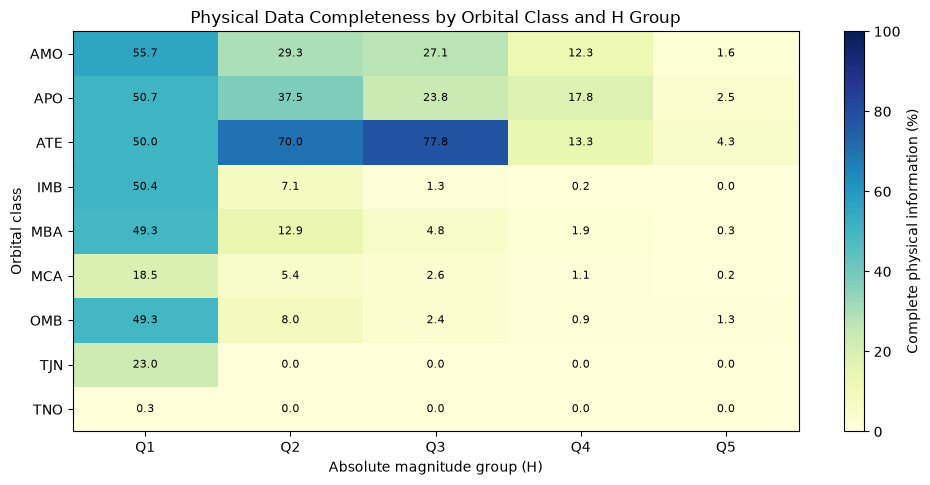

In [7]:
# ============================================================
# PLOT 1. PHYSICAL COMPLETENESS HEATMAP
# ============================================================

plot_data = physical_pivot_pct.dropna(how="all")

if not plot_data.empty:

    fig, ax = plt.subplots(
        figsize=(10, max(4, 0.55 * len(plot_data)))
    )

    image = ax.imshow(
        plot_data.to_numpy(dtype=float),
        aspect="auto",
        cmap="YlGnBu",
        vmin=0,
        vmax=100
    )

    ax.set_xticks(range(len(plot_data.columns)))
    ax.set_xticklabels(plot_data.columns)
    ax.set_yticks(range(len(plot_data.index)))
    ax.set_yticklabels(plot_data.index)

    ax.set_xlabel("Absolute magnitude group (H)")
    ax.set_ylabel("Orbital class")
    ax.set_title(
        "Physical Data Completeness by Orbital Class and H Group"
    )

    for row in range(plot_data.shape[0]):
        for col in range(plot_data.shape[1]):
            value = plot_data.iloc[row, col]
            if pd.notna(value):
                ax.text(
                    col, row, f"{value:.1f}",
                    ha="center", va="center",
                    fontsize=8
                )

    fig.colorbar(
        image,
        ax=ax,
        label="Complete physical information (%)"
    )

    plt.tight_layout()
    fig.savefig(RESULT_DIR / "01_completeness_heatmap.png", dpi=180, bbox_inches="tight")
    plt.show()

else:
    print("Không có dữ liệu để vẽ heatmap.")

**Hình 2.** Nhóm nằm về phía bên phải có tỷ lệ đầy đủ thông tin vật lý cao hơn; nhóm nằm thấp hơn có độ bất định tương đối nhỏ hơn. Hai đặc điểm này được xem xét độc lập, không gộp thành một điểm chất lượng duy nhất.

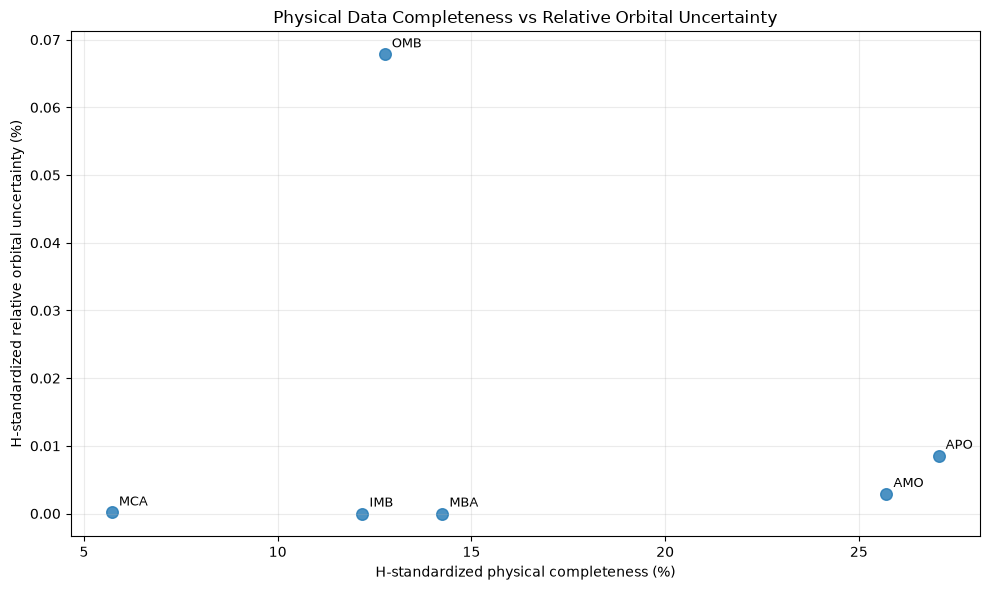

In [8]:
# ============================================================
# PLOT 2. COMPLETENESS VS ORBITAL UNCERTAINTY
# ============================================================

comparison_plot = pd.concat(
    [
        physical_result["Standardized rate (%)"],
        sigma_result["Weighted stratum medians (%)"]
    ],
    axis=1,
    join="inner"
).dropna()

comparison_plot.columns = [
    "Physical completeness (%)",
    "Relative orbital uncertainty (%)"
]

if not comparison_plot.empty:

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.scatter(
        comparison_plot["Physical completeness (%)"],
        comparison_plot["Relative orbital uncertainty (%)"],
        s=70,
        alpha=0.8
    )

    for class_name, row in comparison_plot.iterrows():
        ax.annotate(
            str(class_name),
            (
                row["Physical completeness (%)"],
                row["Relative orbital uncertainty (%)"]
            ),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=9
        )

    ax.set_xlabel("H-standardized physical completeness (%)")
    ax.set_ylabel("H-standardized relative orbital uncertainty (%)")
    ax.set_title(
        "Physical Data Completeness vs Relative Orbital Uncertainty"
    )

    ax.grid(alpha=0.25)
    plt.tight_layout()
    fig.savefig(RESULT_DIR / "02_completeness_uncertainty.png", dpi=180, bbox_inches="tight")
    plt.show()

else:
    print("Không đủ nhóm có kết quả chuẩn hóa để vẽ biểu đồ.")

### Kết luận Q1

Trong 6 nhóm đủ điều kiện so sánh, sau khi chuẩn hóa theo cùng cơ cấu độ sáng tuyệt đối H, APO có tỷ lệ đầy đủ thông tin vật lý cao nhất theo ước lượng điểm (27,06%), tiếp theo là AMO (25,71%). Tuy nhiên, chưa đủ bằng chứng để khẳng định APO vượt AMO rõ rệt vì chưa kiểm định trực tiếp chênh lệch giữa hai nhóm.

IMB có chỉ số độ bất định tương đối của bán trục lớn thấp nhất, khoảng 9,60 × 10⁻⁷%, tiếp theo là MBA với 3,87 × 10⁻⁶%. Chỉ số này được tính bằng trung bình có trọng số của các trung vị theo tầng H.

Chuẩn hóa H làm thay đổi thứ hạng: OMB đứng đầu về tỷ lệ đầy đủ thông tin vật lý trước chuẩn hóa nhưng xuống thứ tư sau chuẩn hóa, trong khi APO từ thứ ba lên thứ nhất. Điều này cho thấy cần xét cơ cấu H khi so sánh các nhóm. Thứ hạng về mức đầy đủ thông tin vật lý và độ bất định tương đối vẫn giữ nguyên khi chia H thành 4, 5 hoặc 6 tầng.

Mẫu bổ sung NASA/JPL ghép thành công 190/217 đối tượng và cho thấy lịch sử quan sát khác nhau giữa các nhóm và tầng H. Tuy nhiên, do mẫu nhỏ và còn bản ghi chưa ghép được, kết quả này chỉ dùng làm bối cảnh bổ trợ, không chứng minh quan hệ nhân quả.

## Phụ lục · Khoảng tin cậy, kiểm tra độ ổn định và bảng chi tiết

### Khoảng tin cậy bootstrap 95%

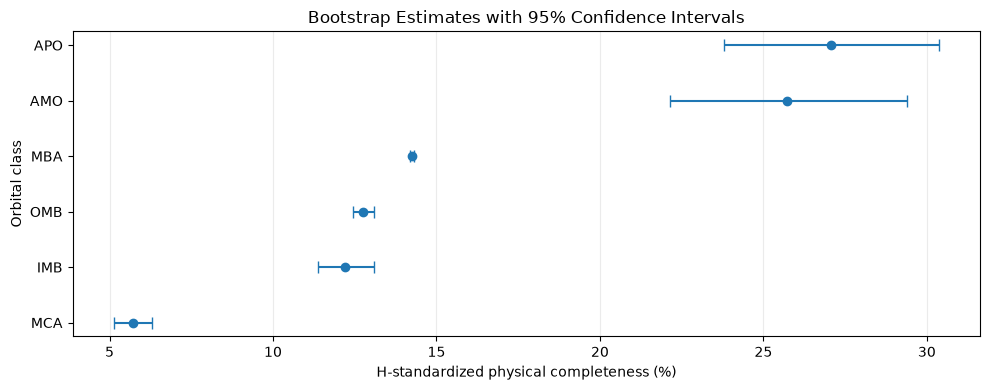

In [9]:
# ============================================================
# PLOT 3. BOOTSTRAP CONFIDENCE INTERVALS
# ============================================================

if not bootstrap_physical.empty:

    plot_ci = bootstrap_physical.sort_values(
        "estimate", ascending=True
    ).copy()

    y_pos = np.arange(len(plot_ci))

    lower_error = (
        plot_ci["estimate"] - plot_ci["CI_lower"]
    ).clip(lower=0)

    upper_error = (
        plot_ci["CI_upper"] - plot_ci["estimate"]
    ).clip(lower=0)

    fig, ax = plt.subplots(
        figsize=(10, max(4, 0.55 * len(plot_ci)))
    )

    ax.errorbar(
        plot_ci["estimate"],
        y_pos,
        xerr=np.vstack([lower_error, upper_error]),
        fmt="o",
        capsize=4
    )

    ax.set_yticks(y_pos)
    ax.set_yticklabels(plot_ci["class"])
    ax.set_xlabel("H-standardized physical completeness (%)")
    ax.set_ylabel("Orbital class")
    ax.set_title(
        "Bootstrap Estimates with 95% Confidence Intervals"
    )

    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    fig.savefig(RESULT_DIR / "03_bootstrap_intervals.png", dpi=180, bbox_inches="tight")
    plt.show()

else:
    print("Không có kết quả Bootstrap để vẽ biểu đồ.")

In [10]:
# ============================================================
# 7. AUTOMATIC ANSWER AND INTERPRETATION FROM REAL RESULTS
# ============================================================

def _fmt(value, digits=2):
    if pd.isna(value):
        return "NA"
    return f"{value:,.{digits}f}"

def _top_line(table, value_col, lower_is_better=False, label=""):
    if table is None or table.empty or value_col not in table.columns:
        return f"- {label}: chưa đủ nhóm hợp lệ để kết luận."
    ordered = table.sort_values(value_col, ascending=lower_is_better)
    winner = ordered.iloc[0]
    return (
        f"- {label}: **{ordered.index[0]}** "
        f"({_fmt(winner[value_col], 4)}). "
        f"So sánh được trên {len(ordered)} nhóm đủ điều kiện."
    )

answer_lines = [
    "# Kết quả trả lời câu hỏi Q1",
    "",
    "## 1. Quy mô và chất lượng dữ liệu",
    f"- Dataset sau tiền xử lý có **{len(df):,} dòng** và **{df.shape[1]} cột**.",
    f"- Tỷ lệ bản ghi có đồng thời `diameter` và `albedo` hợp lệ là **{df['physical_complete'].mean() * 100:.2f}%**.",
    f"- Mẫu phân tích chính sau khi yêu cầu `class` và `H_bin` hợp lệ, đồng thời áp dụng ngưỡng quy mô nhóm, có **{len(analysis_df):,} dòng** thuộc **{analysis_df['class'].nunique()} nhóm quỹ đạo**.",
    "",
    "## 2. Kết quả so sánh sau chuẩn hóa theo H",
    _top_line(
        physical_result, "Standardized rate (%)",
        lower_is_better=False,
        label="Tỷ lệ đầy đủ thông tin vật lý cao nhất"
    ),
    _top_line(
        sigma_result, "Weighted stratum medians (%)",
        lower_is_better=True,
        label="Độ bất định tương đối của bán trục lớn thấp nhất"
    ),
    _top_line(
        rms_result, "Weighted stratum medians RMS",
        lower_is_better=True,
        label="RMS chuẩn hóa thấp nhất"
    ),
    ""
]

if not physical_result.empty:
    n_changed = int((physical_result["Rank change"] != 0).sum())
    answer_lines.append(
        f"- Sau chuẩn hóa H, **{n_changed}/{len(physical_result)} nhóm** "
        "thay đổi thứ hạng về tỷ lệ đầy đủ thông tin vật lý so với thứ hạng thô."
    )
if not sigma_result.empty:
    n_changed = int((sigma_result["Rank change"] != 0).sum())
    answer_lines.append(
        f"- Với độ bất định tương đối, **{n_changed}/{len(sigma_result)} nhóm** "
        "thay đổi thứ hạng sau chuẩn hóa H."
    )
if not rms_result.empty:
    n_changed = int((rms_result["Rank change"] != 0).sum())
    answer_lines.append(
        f"- Với RMS, **{n_changed}/{len(rms_result)} nhóm** "
        "thay đổi thứ hạng sau chuẩn hóa H."
    )

answer_lines += ["", "## 3. Độ bất định của ước lượng (Bootstrap 95%)"]
if not bootstrap_physical.empty:
    for _, row in bootstrap_physical.sort_values("estimate", ascending=False).iterrows():
        answer_lines.append(
            f"- **{row['class']}**: {_fmt(row['estimate'], 2)}% "
            f"(95% CI: {_fmt(row['CI_lower'], 2)}%–{_fmt(row['CI_upper'], 2)}%; "
            f"n hợp lệ trong các tầng: {int(row['n_valid']):,})."
        )
else:
    answer_lines.append("- Không có nhóm đủ điều kiện để tính khoảng Bootstrap cho tỷ lệ đầy đủ vật lý.")

answer_lines += ["", "## 4. Kiểm tra độ ổn định"]
if "robustness_all" in globals() and not robustness_all.empty:
    for metric, block in robustness_all.groupby("metric"):
        answer_lines.append(f"- **{metric}**:")
        for _, row in block.iterrows():
            rho_text = "không tính được" if pd.isna(row["rank_correlation"]) else _fmt(row["rank_correlation"], 3)
            answer_lines.append(
                f"  - Chia {int(row['H_bins'])} tầng H: "
                f"{int(row['eligible_classes'])} nhóm đủ điều kiện; "
                f"{int(row['common_classes'])} nhóm chung; "
                f"tương quan thứ hạng Spearman = {rho_text}."
            )
else:
    answer_lines.append("- Chạy cell kiểm tra độ ổn định ở phần 8 để có kết quả.")

if "threshold_result" in globals() and not threshold_result.empty:
    answer_lines.append("- Khi thay ngưỡng quy mô nhóm:")
    for _, row in threshold_result.iterrows():
        top = row["Top-ranked class"] if pd.notna(row["Top-ranked class"]) else "không có nhóm đủ điều kiện"
        answer_lines.append(
            f"  - Ngưỡng {int(row['Minimum class size']):,}: "
            f"{int(row['Comparable classes'])} nhóm so sánh được; "
            f"nhóm đứng đầu = {top}."
        )

answer_lines += ["", "## 5. Bằng chứng bổ sung từ NASA/JPL"]
if "merged_df" in globals() and not merged_df.empty and "_merge" in merged_df.columns:
    matched_n = int((merged_df["_merge"] == "both").sum())
    total_n = len(merged_df)
    rate = 100 * matched_n / total_n if total_n else np.nan
    answer_lines.append(
        f"- Ghép thành công **{matched_n}/{total_n}** đối tượng "
        f"({rate:.2f}%); số dòng trước và sau ghép lần lượt là "
        f"{rows_before_merge:,} và {rows_after_merge:,}."
    )
    if rate < 50:
        answer_lines.append(
            "- **Cảnh báo:** tỷ lệ ghép dưới 50%; lịch sử quan sát JPL chỉ được xem "
            "là bằng chứng minh họa trên mẫu ghép nhỏ, không khái quát cho toàn dataset."
        )
    if not jpl_summary.empty:
        answer_lines.append(
            f"- Có {len(jpl_matched):,} bản ghi ghép được đưa vào bảng tổng hợp lịch sử quan sát."
        )
        answer_lines.append(
            "- Bảng `jpl_summary` cung cấp trung vị số quan sát, độ dài cung quan sát, "
            "cường độ quan sát và condition code theo `class × H_bin`."
        )
else:
    answer_lines.append(
        "- Không có bản ghi JPL ghép thành công trong lần chạy này; "
        "không đưa ra kết luận về lịch sử quan sát."
    )

answer_lines += [
    "",
    "## 6. Kết luận và giới hạn diễn giải",
    "- Tỷ lệ đầy đủ thông tin vật lý, độ bất định tương đối của bán trục lớn và RMS "
    "là ba khía cạnh khác nhau; không gộp thành một thước đo chất lượng duy nhất.",
    "- Kết quả chuẩn hóa trả lời câu hỏi liệu thứ hạng giữa các nhóm có thay đổi "
    "khi đặt chúng dưới cùng cơ cấu H hay không. Chỉ diễn giải trên các nhóm đủ "
    "quan sát ở mọi tầng H.",
    "- Bootstrap mô tả độ biến động tái lấy mẫu có điều kiện; không loại bỏ sai lệch "
    "chọn mẫu và không phải kiểm định nhân quả.",
    "- NASA/JPL chỉ là nguồn bổ sung trên mẫu chọn lọc. Nếu tỷ lệ ghép thấp hoặc số "
    "quan sát nhỏ, không suy rộng kết quả JPL cho toàn bộ nhóm.",
    "- Không kết luận nhóm nào 'tốt nhất toàn diện' nếu nhóm đó không đồng thời đứng "
    "đầu ở tất cả chỉ số."
]

final_answer = "\n".join(answer_lines)
display(Markdown(final_answer))
(RESULT_DIR / "q1_answer_interpretation.md").write_text(
    final_answer, encoding="utf-8"
)


# Kết quả trả lời câu hỏi Q1

## 1. Quy mô và chất lượng dữ liệu
- Dataset sau tiền xử lý có **958,524 dòng** và **48 cột**.
- Tỷ lệ bản ghi có đồng thời `diameter` và `albedo` hợp lệ là **14.09%**.
- Mẫu phân tích chính sau khi yêu cầu `class` và `H_bin` hợp lệ, đồng thời áp dụng ngưỡng quy mô nhóm, có **951,672 dòng** thuộc **9 nhóm quỹ đạo**.

## 2. Kết quả so sánh sau chuẩn hóa theo H
- Tỷ lệ đầy đủ thông tin vật lý cao nhất: **APO** (27.0594). So sánh được trên 6 nhóm đủ điều kiện.
- Độ bất định tương đối của bán trục lớn thấp nhất: **IMB** (0.0000). So sánh được trên 6 nhóm đủ điều kiện.
- RMS chuẩn hóa thấp nhất: **APO** (0.4732). So sánh được trên 6 nhóm đủ điều kiện.

- Sau chuẩn hóa H, **4/6 nhóm** thay đổi thứ hạng về tỷ lệ đầy đủ thông tin vật lý so với thứ hạng thô.
- Với độ bất định tương đối, **4/6 nhóm** thay đổi thứ hạng sau chuẩn hóa H.
- Với RMS, **3/6 nhóm** thay đổi thứ hạng sau chuẩn hóa H.

## 3. Độ bất định của ước lượng (Bootstrap 95%)
- **APO**: 27.06% (95% CI: 23.79%–30.36%; n hợp lệ trong các tầng: 12,684).
- **AMO**: 25.71% (95% CI: 22.14%–29.38%; n hợp lệ trong các tầng: 8,449).
- **MBA**: 14.25% (95% CI: 14.19%–14.32%; n hợp lệ trong các tầng: 851,173).
- **OMB**: 12.77% (95% CI: 12.44%–13.09%; n hợp lệ trong các tầng: 27,710).
- **IMB**: 12.19% (95% CI: 11.39%–13.09%; n hợp lệ trong các tầng: 20,159).
- **MCA**: 5.72% (95% CI: 5.13%–6.31%; n hợp lệ trong các tầng: 18,118).

## 4. Kiểm tra độ ổn định
- **physical_complete**:
  - Chia 4 tầng H: 6 nhóm đủ điều kiện; 6 nhóm chung; tương quan thứ hạng Spearman = 1.000.
  - Chia 5 tầng H: 6 nhóm đủ điều kiện; 6 nhóm chung; tương quan thứ hạng Spearman = 1.000.
  - Chia 6 tầng H: 6 nhóm đủ điều kiện; 6 nhóm chung; tương quan thứ hạng Spearman = 1.000.
- **relative_sigma_a_pct**:
  - Chia 4 tầng H: 6 nhóm đủ điều kiện; 6 nhóm chung; tương quan thứ hạng Spearman = 1.000.
  - Chia 5 tầng H: 6 nhóm đủ điều kiện; 6 nhóm chung; tương quan thứ hạng Spearman = 1.000.
  - Chia 6 tầng H: 6 nhóm đủ điều kiện; 6 nhóm chung; tương quan thứ hạng Spearman = 1.000.
- **rms**:
  - Chia 4 tầng H: 6 nhóm đủ điều kiện; 6 nhóm chung; tương quan thứ hạng Spearman = 1.000.
  - Chia 5 tầng H: 6 nhóm đủ điều kiện; 6 nhóm chung; tương quan thứ hạng Spearman = 1.000.
  - Chia 6 tầng H: 6 nhóm đủ điều kiện; 6 nhóm chung; tương quan thứ hạng Spearman = 0.943.
- Khi thay ngưỡng quy mô nhóm:
  - Ngưỡng 500: 6 nhóm so sánh được; nhóm đứng đầu = APO.
  - Ngưỡng 1,000: 6 nhóm so sánh được; nhóm đứng đầu = APO.
  - Ngưỡng 2,000: 6 nhóm so sánh được; nhóm đứng đầu = APO.

## 5. Bằng chứng bổ sung từ NASA/JPL
- Ghép thành công **190/217** đối tượng (87.56%); số dòng trước và sau ghép lần lượt là 217 và 217.
- Có 190 bản ghi ghép được đưa vào bảng tổng hợp lịch sử quan sát.
- Bảng `jpl_summary` cung cấp trung vị số quan sát, độ dài cung quan sát, cường độ quan sát và condition code theo `class × H_bin`.

## 6. Kết luận và giới hạn diễn giải
- Tỷ lệ đầy đủ thông tin vật lý, độ bất định tương đối của bán trục lớn và RMS là ba khía cạnh khác nhau; không gộp thành một thước đo chất lượng duy nhất.
- Kết quả chuẩn hóa trả lời câu hỏi liệu thứ hạng giữa các nhóm có thay đổi khi đặt chúng dưới cùng cơ cấu H hay không. Chỉ diễn giải trên các nhóm đủ quan sát ở mọi tầng H.
- Bootstrap mô tả độ biến động tái lấy mẫu có điều kiện; không loại bỏ sai lệch chọn mẫu và không phải kiểm định nhân quả.
- NASA/JPL chỉ là nguồn bổ sung trên mẫu chọn lọc. Nếu tỷ lệ ghép thấp hoặc số quan sát nhỏ, không suy rộng kết quả JPL cho toàn bộ nhóm.
- Không kết luận nhóm nào 'tốt nhất toàn diện' nếu nhóm đó không đồng thời đứng đầu ở tất cả chỉ số.

3622

In [11]:
# ============================================================
# 8. EXTENDED ROBUSTNESS, HISTORY AUDIT AND EXPORTS
# ============================================================

print("Robustness across 4, 5 and 6 H groups:")
display(robustness_all)


# Audit the matched JPL sample and describe observation history only if matched.
history_quality = pd.DataFrame()
if "jpl_matched" in globals() and not jpl_matched.empty:
    history_quality = (
        jpl_matched
        .groupby(["class", "H_bin"], observed=True)
        .agg(
            matched=("merge_key", "size"),
            valid_n_obs=("n_obs_used", "count"),
            valid_data_arc=("data_arc", "count"),
            valid_condition_code=("condition_code", "count")
        )
        .reset_index()
    )
    print("JPL history data availability by class × H group:")
    display(history_quality)

    if "class_jpl" in jpl_matched.columns:
        class_mismatch = int(
            (
                jpl_matched["class"].astype(str)
                != jpl_matched["class_jpl"].astype(str)
            ).sum()
        )
        print("Rows with different Kaggle/JPL class labels:", class_mismatch)
else:
    print("No matched JPL observations available for history audit.")


# Export all tables used in sections 5–7.
exports = {
    "physical_result": physical_result,
    "sigma_result": sigma_result,
    "rms_result": rms_result,
    "eligibility_audit": eligibility_audit,
    "cell_summary": cell_summary,
    "physical_pivot_pct": physical_pivot_pct,
    "sigma_pivot": sigma_pivot,
    "rms_pivot": rms_pivot,
    "count_pivot": count_pivot,
    "bootstrap_physical": bootstrap_physical,
    "bootstrap_sigma": bootstrap_sigma,
    "bootstrap_rms": bootstrap_rms,
    "robustness_all": robustness_all,
    "threshold_result": threshold_result,
    "jpl_summary": jpl_summary,
    "history_quality": history_quality,
    "condition_result": condition_result
}

for name, table in exports.items():
    if isinstance(table, pd.DataFrame):
        table.to_csv(
            RESULT_DIR / f"{name}.csv",
            index=True
        )

# Store reproducibility metadata and dataset fingerprint.
hasher = hashlib.sha256()
with DATA_PATH.open("rb") as stream:
    for chunk in iter(lambda: stream.read(1024 * 1024), b""):
        hasher.update(chunk)

manifest = {
    "run_utc": datetime.now(timezone.utc).isoformat(),
    "dataset_sha256": hasher.hexdigest(),
    "dataset_path": str(DATA_PATH.resolve()),
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "n_boot": N_BOOT,
    "seed": RANDOM_SEED,
    "min_class_size": MIN_CLASS_SIZE,
    "min_cell_size": MIN_CELL_SIZE,
    "reference_H_weights": h_weights.to_dict(),
    "jpl_fetch_enabled": FETCH_JPL,
    "jpl_lookup_column": jpl_lookup_col,
    "jpl_matched_rows": int(len(jpl_matched)) if "jpl_matched" in globals() else 0
}
(RESULT_DIR / "run_manifest.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2, default=str),
    encoding="utf-8"
)

print("Saved analysis tables, figures, answer and run metadata to:")
print(RESULT_DIR.resolve())


Robustness across 4, 5 and 6 H groups:


,metric,H_bins,eligible_classes,common_classes,rank_correlation
0,physical_complete,4,6,6,1.000000
1,physical_complete,5,6,6,1.000000
2,physical_complete,6,6,6,1.000000
3,relative_sigma_a_pct,4,6,6,1.000000
4,relative_sigma_a_pct,5,6,6,1.000000
5,relative_sigma_a_pct,6,6,6,1.000000
6,rms,4,6,6,1.000000
7,rms,5,6,6,1.000000
8,rms,6,6,6,0.942857


JPL history data availability by class × H group:


,class,H_bin,matched,valid_n_obs,valid_data_arc,valid_condition_code
0,AMO,Q1,5,5,5,5
1,AMO,Q2,5,5,5,5
2,AMO,Q3,5,5,5,5
3,AMO,Q4,5,5,5,5
4,AMO,Q5,5,5,5,5
5,APO,Q1,5,5,5,5
6,APO,Q2,5,5,5,5
7,APO,Q3,5,5,5,5
8,APO,Q4,3,3,3,3
9,APO,Q5,4,4,4,4


Rows with different Kaggle/JPL class labels: 4
Saved analysis tables, figures, answer and run metadata to:
/home/hohuunghiem/LTKHDL/P4DS/data/processed/q1_results
